In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Load the CSV file
df = pd.read_csv("../data/fake_job_postings.csv")

# 1. Shape of the dataset
print("Shape (rows, columns):", df.shape)

# 2. Column names, non-null counts and data types
print("\n--- Info ---")
df.info()

# 3. Target distribution (0 = genuine, 1 = fraudulent)
print("\n--- Target counts ---")
print(df["fraudulent"].value_counts())
print("\n--- Target percentage ---")
print((df["fraudulent"].value_counts(normalize=True) * 100).round(2))

# 4. Missing values (count and percentage)
print("\n--- Missing values ---")
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("Missing Count", ascending=False)
print(missing)

# 5. Duplicate rows (ignoring job_id, since it is unique for every row)
print("\n--- Duplicates ---")
print("Duplicate rows (without job_id):", df.drop(columns=["job_id"]).duplicated().sum())

Shape (rows, columns): (17880, 18)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-n

In [3]:
# Target distribution: 0 = genuine, 1 = fraudulent
print(df["fraudulent"].value_counts())
print()
print((df["fraudulent"].value_counts(normalize=True) * 100).round(2))

fraudulent
0    17014
1      866
Name: count, dtype: int64

fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


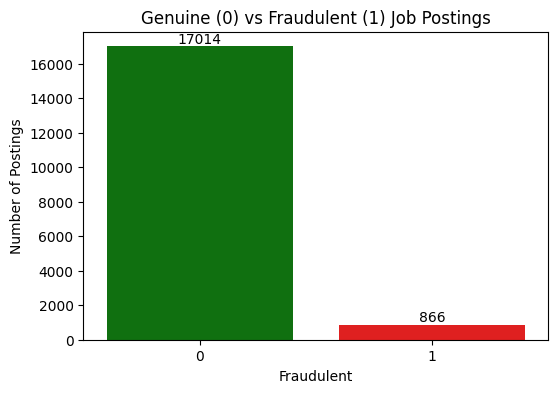

In [4]:
# Count plot of the target column
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="fraudulent", data=df, palette=["green", "red"])
plt.title("Genuine (0) vs Fraudulent (1) Job Postings")
plt.xlabel("Fraudulent")
plt.ylabel("Number of Postings")

# Write the count on top of each bar
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()


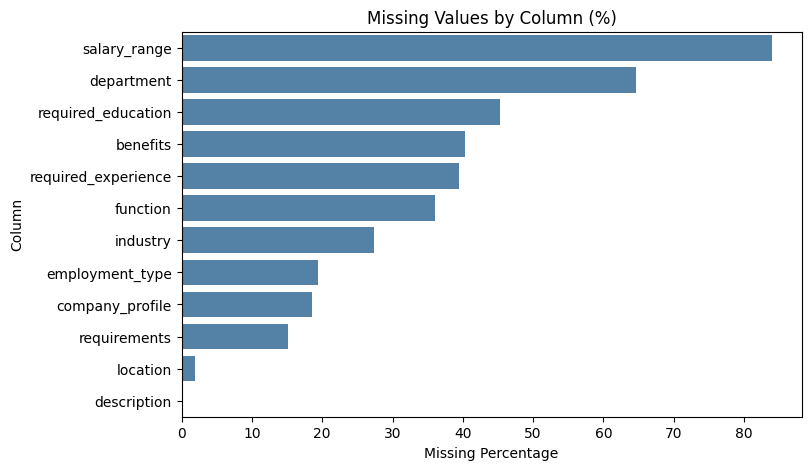

In [5]:
# Percentage of missing values per column (only columns that have missing values)
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(8, 5))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")
plt.title("Missing Values by Column (%)")
plt.xlabel("Missing Percentage")
plt.ylabel("Column")
plt.show()

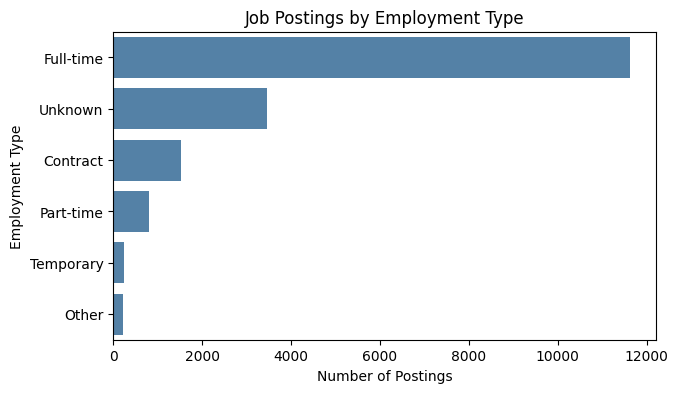

In [6]:
# Number of postings in each employment type (missing shown as "Unknown")
plt.figure(figsize=(7, 4))
order = df["employment_type"].fillna("Unknown").value_counts().index
sns.countplot(y=df["employment_type"].fillna("Unknown"), order=order, color="steelblue")
plt.title("Job Postings by Employment Type")
plt.xlabel("Number of Postings")
plt.ylabel("Employment Type")
plt.show()

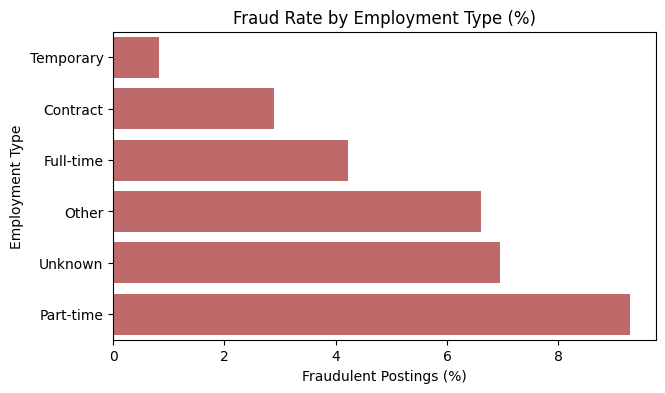

In [7]:
# Fraud percentage inside each employment type
# (mean of a 0/1 column = fraction of 1s)
fraud_rate = (df.assign(employment_type=df["employment_type"].fillna("Unknown"))
                .groupby("employment_type")["fraudulent"].mean() * 100).sort_values()

plt.figure(figsize=(7, 4))
sns.barplot(x=fraud_rate.values, y=fraud_rate.index, color="indianred")
plt.title("Fraud Rate by Employment Type (%)")
plt.xlabel("Fraudulent Postings (%)")
plt.ylabel("Employment Type")
plt.show()


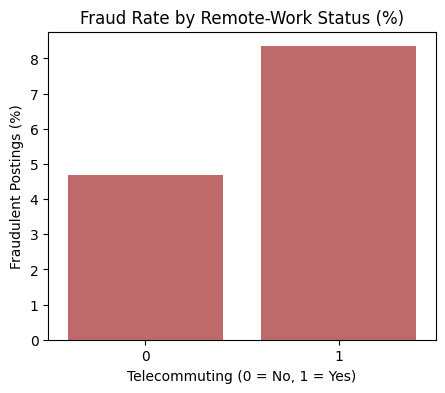

In [8]:
# telecommuting: 1 = remote work possible, 0 = not remote
fraud_remote = df.groupby("telecommuting")["fraudulent"].mean() * 100

plt.figure(figsize=(5, 4))
sns.barplot(x=fraud_remote.index, y=fraud_remote.values, color="indianred")
plt.title("Fraud Rate by Remote-Work Status (%)")
plt.xlabel("Telecommuting (0 = No, 1 = Yes)")
plt.ylabel("Fraudulent Postings (%)")
plt.show()

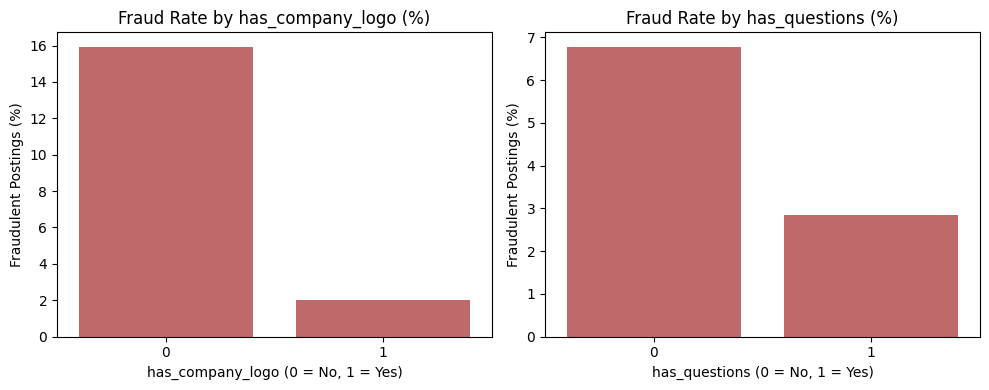

In [9]:
# Two more useful binary columns: has_company_logo and has_questions
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ["has_company_logo", "has_questions"]):
    rate = df.groupby(col)["fraudulent"].mean() * 100
    sns.barplot(x=rate.index, y=rate.values, color="indianred", ax=ax)
    ax.set_title(f"Fraud Rate by {col} (%)")
    ax.set_xlabel(f"{col} (0 = No, 1 = Yes)")
    ax.set_ylabel("Fraudulent Postings (%)")

plt.tight_layout()
plt.show()

In [10]:
# All columns except job_id (job_id is unique for every row)
content_cols = [c for c in df.columns if c != "job_id"]

# keep=False marks ALL copies of a duplicated posting
dup_mask = df.duplicated(subset=content_cols, keep=False)
dups = df[dup_mask]
print("Rows involved in duplicates:", len(dups))

# Do any duplicate groups have different labels (one genuine, one fraud)?
conflict = dups.groupby(content_cols, dropna=False)["fraudulent"].nunique()
print("Duplicate groups:", len(conflict))
print("Groups with conflicting labels:", (conflict > 1).sum())

Rows involved in duplicates: 527
Duplicate groups: 246
Groups with conflicting labels: 0


In [11]:
# Remove exact duplicate postings, keep only the first copy.
# Justification: if a copy lands in the test set while its twin is in the
# training set, the model has effectively seen the answer (data leakage).
df_clean = df.drop_duplicates(subset=content_cols, keep="first").reset_index(drop=True)

print("Rows before:", len(df))
print("Rows after :", len(df_clean))
print()
print(df_clean["fraudulent"].value_counts())
print((df_clean["fraudulent"].value_counts(normalize=True) * 100).round(2))

Rows before: 17880
Rows after : 17599

fraudulent
0    16743
1      856
Name: count, dtype: int64
fraudulent
0    95.14
1     4.86
Name: proportion, dtype: float64


In [12]:
# Work on a copy so the original df stays untouched
data = df_clean.copy()

# --- Text columns: fill missing with empty string and join into one column ---
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
for c in text_cols:
    data[c] = data[c].fillna("")
data["text"] = data[text_cols].agg(" ".join, axis=1)

# --- Salary: only keep whether a salary was mentioned (1) or not (0) ---
data["has_salary"] = data["salary_range"].notna().astype(int)

# --- Location: keep only the country code (text before the first comma) ---
data["country"] = data["location"].fillna("Unknown").str.split(",").str[0].str.strip()

# --- Categorical columns: missing becomes "Unknown" ---
# (a fixed constant, not learned from data, so no leakage)
cat_cols = ["employment_type", "required_experience", "required_education",
            "industry", "function", "country"]
for c in cat_cols:
    data[c] = data[c].fillna("Unknown")

# --- Numeric / binary columns ---
num_cols = ["telecommuting", "has_company_logo", "has_questions", "has_salary"]

# Final input features (X) and target (y). The target is NOT in X.
feature_cols = ["text"] + cat_cols + num_cols
X = data[feature_cols]
y = data["fraudulent"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Is target inside X?", "fraudulent" in X.columns)
X.head(3)

X shape: (17599, 11)
y shape: (17599,)
Is target inside X? False


,text,employment_type,required_experience,required_education,industry,function,country,telecommuting,has_company_logo,has_questions,has_salary
0,"Marketing Intern We're Food52, and we've creat...",Other,Internship,Unknown,Unknown,Marketing,US,0,1,0,0
1,Customer Service - Cloud Video Production 90 S...,Full-time,Not Applicable,Unknown,Marketing and Advertising,Customer Service,NZ,0,1,0,0
2,Commissioning Machinery Assistant (CMA) Valor ...,Unknown,Unknown,Unknown,Unknown,Unknown,US,0,1,0,0


In [13]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42  # fixed seed so results are repeatable

# stratify=y keeps the same fraud percentage in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size :", X_test.shape[0])
print()
print("Fraud % in train:", round(y_train.mean() * 100, 2))
print("Fraud % in test :", round(y_test.mean() * 100, 2))

Train size: 14079
Test size : 3520

Fraud % in train: 4.87
Fraud % in test : 4.86


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        # Text -> TF-IDF numbers (top 5000 words, English stop words removed)
        ("text", TfidfVectorizer(stop_words="english", max_features=5000, min_df=5), "text"),
        # Categories -> 0/1 columns (rare categories grouped, unseen ones ignored)
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_cols),
        # Binary columns are already 0/1, so pass them as they are
        ("num", "passthrough", num_cols),
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('text',
                                 TfidfVectorizer(max_features=5000, min_df=5,
                                                 stop_words='english'),
                                 'text'),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               min_frequency=20),
                                 ['employment_type', 'required_experience',
                                  'required_education', 'industry', 'function',
                                  'country']),
                                ('num', 'passthrough',
                                 ['telecommuting', 'has_company_logo',
                                  'has_questions', 'has_salary'])])


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

# The four models (same fixed seed wherever applicable)
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM (LinearSVC)": LinearSVC(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
}

# Each pipeline = preprocessing step + model step
pipelines = {
    name: Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
    for name, model in models.items()
}

print("Pipelines created:", list(pipelines.keys()))

Pipelines created: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM (LinearSVC)']


In [16]:
import time

trained = {}  # will store the fitted pipelines

for name, pipe in pipelines.items():
    start = time.time()
    # fit() learns the preprocessing AND the model using ONLY the training data
    pipe.fit(X_train, y_train)
    trained[name] = pipe
    
    print(f"{name} trained in {time.time() - start:.1f} seconds")

Logistic Regression trained in 11.4 seconds
Decision Tree trained in 23.8 seconds
Random Forest trained in 25.5 seconds
SVM (LinearSVC) trained in 11.6 seconds


In [17]:
# Predict on the SAME test set for all four models
predictions = {}

for name, pipe in trained.items():
    # transform() on test data uses what was learned from training data only
    predictions[name] = pipe.predict(X_test)
    print(f"{name}: predicted {len(predictions[name])} test postings")

Logistic Regression: predicted 3520 test postings
Decision Tree: predicted 3520 test postings
Random Forest: predicted 3520 test postings
SVM (LinearSVC): predicted 3520 test postings


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        # pos_label=1 means we measure performance on the fraudulent class
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    })

# Build the table from the real predictions (nothing is hardcoded)
results = pd.DataFrame(rows).round(4).sort_values("F1-score", ascending=False).reset_index(drop=True)

# Save to the reports folder
results.to_csv("../reports/model_comparison.csv", index=False)
print("Saved to ../reports/model_comparison.csv")
results

Saved to ../reports/model_comparison.csv


,Model,Accuracy,Precision,Recall,F1-score
0,SVM (LinearSVC),0.9801,0.7760,0.8304,0.8023
1,Random Forest,0.9790,1.0000,0.5673,0.7239
2,Logistic Regression,0.9622,0.5688,0.9181,0.7025
3,Decision Tree,0.9693,0.6760,0.7076,0.6914


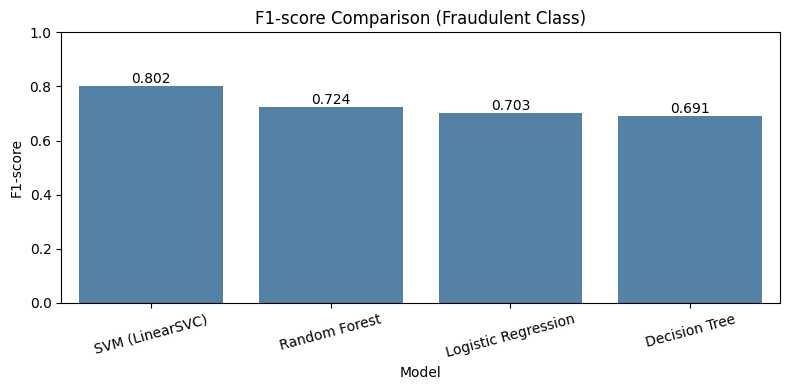

In [19]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(x="Model", y="F1-score", data=results, color="steelblue")
plt.title("F1-score Comparison (Fraudulent Class)")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=15)

# Write the value on top of each bar
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

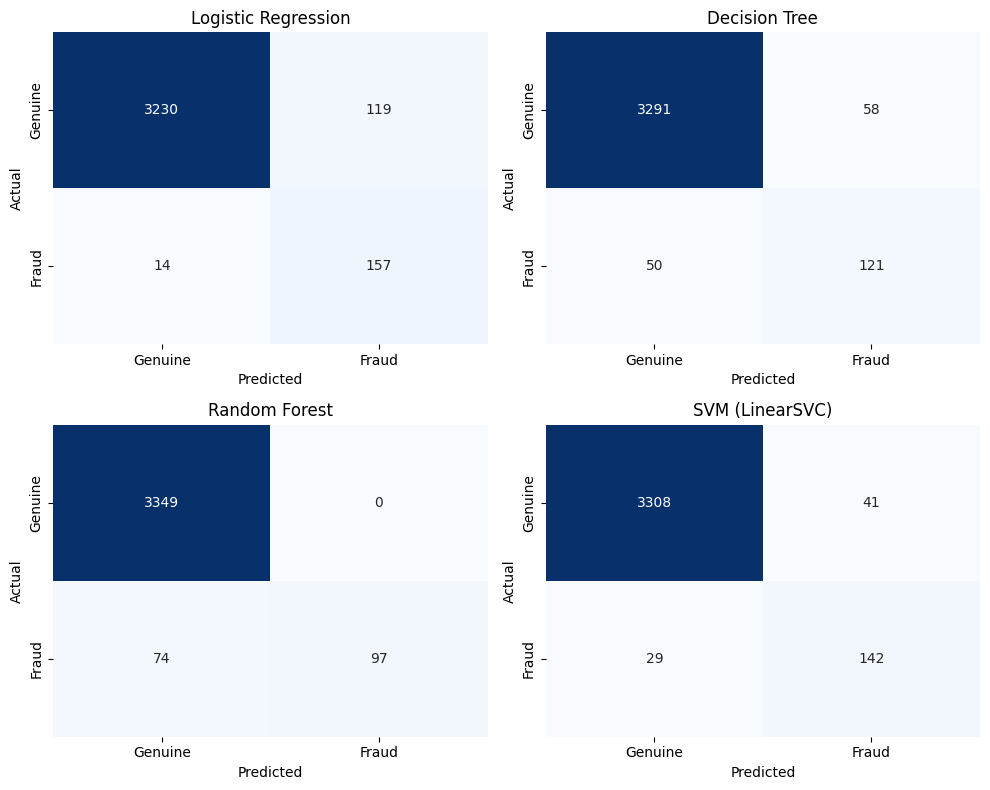

In [20]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Genuine", "Fraud"], yticklabels=["Genuine", "Fraud"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print("=" * 50)
    print(name)
    print(classification_report(y_test, y_pred, target_names=["Genuine", "Fraud"], zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

     Genuine       1.00      0.96      0.98      3349
       Fraud       0.57      0.92      0.70       171

    accuracy                           0.96      3520
   macro avg       0.78      0.94      0.84      3520
weighted avg       0.97      0.96      0.97      3520

Decision Tree
              precision    recall  f1-score   support

     Genuine       0.99      0.98      0.98      3349
       Fraud       0.68      0.71      0.69       171

    accuracy                           0.97      3520
   macro avg       0.83      0.85      0.84      3520
weighted avg       0.97      0.97      0.97      3520

Random Forest
              precision    recall  f1-score   support

     Genuine       0.98      1.00      0.99      3349
       Fraud       1.00      0.57      0.72       171

    accuracy                           0.98      3520
   macro avg       0.99      0.78      0.86      3520
weighted avg       0.98   

In [22]:
# Show the final comparison table (all four models)
results

,Model,Accuracy,Precision,Recall,F1-score
0,SVM (LinearSVC),0.9801,0.7760,0.8304,0.8023
1,Random Forest,0.9790,1.0000,0.5673,0.7239
2,Logistic Regression,0.9622,0.5688,0.9181,0.7025
3,Decision Tree,0.9693,0.6760,0.7076,0.6914


In [23]:
# Numbers needed for the report
print("Rows before removing duplicates:", len(df))
print("Rows after removing duplicates :", len(df_clean))
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("Fraud in train:", int(y_train.sum()), "| Fraud in test:", int(y_test.sum()))
print()

# Confusion matrix numbers for all four models
from sklearn.metrics import confusion_matrix
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Rows before removing duplicates: 17880
Rows after removing duplicates : 17599
Train size: 14079 | Test size: 3520
Fraud in train: 685 | Fraud in test: 171

Logistic Regression: TN=3230, FP=119, FN=14, TP=157
Decision Tree: TN=3291, FP=58, FN=50, TP=121
Random Forest: TN=3349, FP=0, FN=74, TP=97
SVM (LinearSVC): TN=3308, FP=41, FN=29, TP=142
